# African Wildlife Detector
CSCI1409 Deep Learning, bonus project.

Runs from a fresh runtime: installs dependencies, prepares the data, trains two models, compares them on validation, evaluates the final one on test and shows predictions.
Use **Runtime → Change runtime type → T4 GPU** to make training fast (it also works on CPU, just slower).

## 1. Setup

In [11]:
import json, torch, ultralytics
from IPython.display import Image, display
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| cuda", torch.cuda.is_available())

ultralytics 8.4.216 | torch 2.14.1+cpu | cuda False


## 2. Data
Downloads African Wildlife, makes a new group-aware 70/15/15 split (seed 0, near-duplicates stay in the same split) and fixes 5 wrong labels.

In [12]:
!python scripts/prepare_data.py
!python scripts/check_data.py datasets/aw-split

1504 images, 1434 groups, 66 groups with duplicates
train 1053
val 226
test 225
fixed test/val_3_376.txt 3 -> 2
fixed train/train_3_373.txt 3 -> 2
fixed train/train_3_374.txt 3 -> 2
fixed train/train_3_375.txt 3 -> 2
fixed train/train_4_376.txt 0 -> 3
data ready in datasets\aw-split
train images 1053 objects 1890 {'buffalo': 359, 'elephant': 553, 'zebra': 575, 'rhino': 403} empty 0 bad 0
val images 226 objects 410 {'buffalo': 93, 'elephant': 102, 'rhino': 91, 'zebra': 124} empty 0 bad 0
test images 225 objects 385 {'buffalo': 99, 'elephant': 93, 'rhino': 69, 'zebra': 124} empty 0 bad 0
exact duplicate groups: 40 across splits: 0
near-duplicate pairs across splits: 0


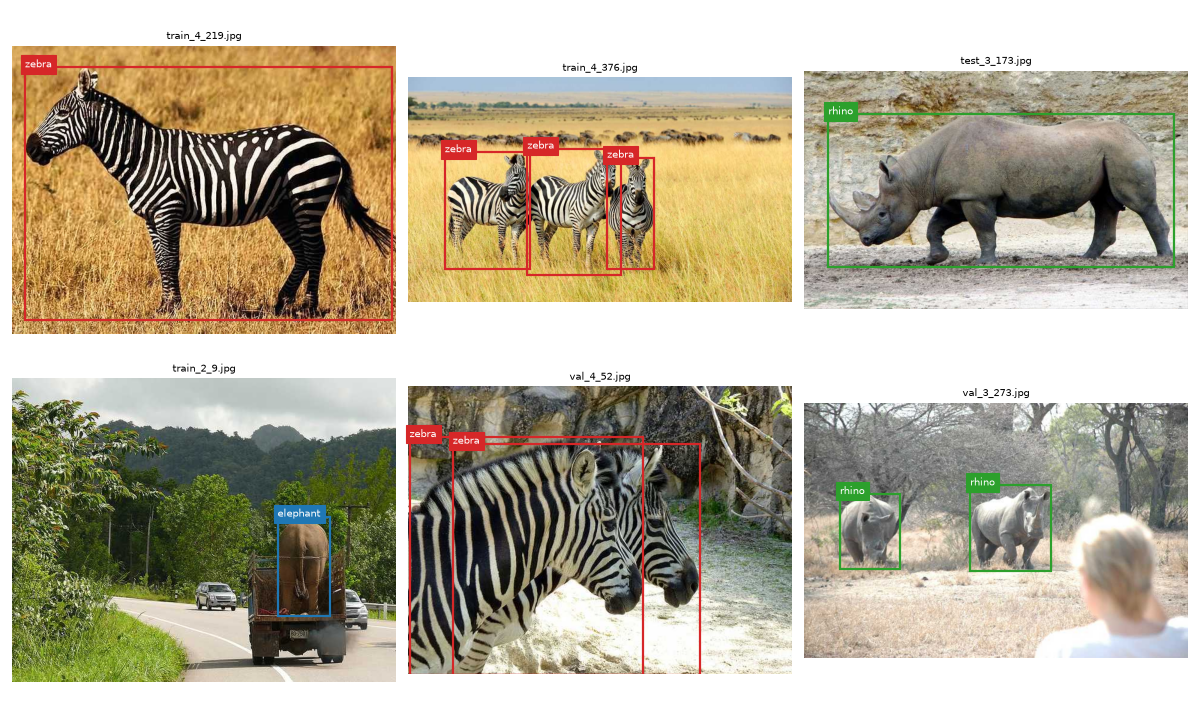

In [13]:
!python scripts/show_gt.py datasets/aw-split results/ground_truth_examples.png
display(Image("results/ground_truth_examples.png"))

## 3. Training
Two runs with the same split, pretrained `yolo11n.pt`, 25 epochs, batch 16, SGD lr0=0.01, seed 0. The only change is image size: 320 vs 416.

Set `TRAIN = False` to skip training and use the weights saved in the repo.

In [ ]:
TRAIN = True
if TRAIN:
    !python scripts/train.py --name baseline_320 --imgsz 320
    !python scripts/train.py --name imgsz_416 --imgsz 416
else:
    !mkdir -p runs/baseline_320/weights runs/imgsz_416/weights
    !cp weights/baseline_320.pt runs/baseline_320/weights/best.pt && cp results/baseline_320/train_time.json runs/baseline_320/
    !cp weights/best.pt runs/imgsz_416/weights/best.pt && cp results/imgsz_416/train_time.json runs/imgsz_416/

^C


In [ ]:
if TRAIN:
    display(Image("runs/baseline_320/results.png"))
    display(Image("runs/imgsz_416/results.png"))
else:
    display(Image("results/baseline_320/results.png"))
    display(Image("results/imgsz_416/results.png"))

FileNotFoundError: No such file or directory: 'runs/baseline_320/results.png'

FileNotFoundError: No such file or directory: 'runs/baseline_320/results.png'

<IPython.core.display.Image object>

FileNotFoundError: No such file or directory: 'runs/imgsz_416/results.png'

FileNotFoundError: No such file or directory: 'runs/imgsz_416/results.png'

<IPython.core.display.Image object>

## 4. Compare on validation

In [ ]:
!python scripts/evaluate.py --split val
val = json.load(open("results/metrics_val.json"))
for run, r in val.items():
    print(f"{run:13s} imgsz {r['imgsz']}  P {r['precision']}  R {r['recall']}  mAP50 {r['mAP50']}  train {r['train_minutes']} min")
final = max(val, key=lambda k: val[k]["mAP50"])
print("final run (best val mAP50):", final)

baseline_320  imgsz 320  P 0.922  R 0.898  mAP50 0.948  train 44.9 min
imgsz_416     imgsz 416  P 0.921  R 0.916  mAP50 0.958  train 76.7 min
final run (best val mAP50): imgsz_416


Traceback (most recent call last):
  File "c:\Users\Admin\Desktop\KBTU\ДЗ\Deep Learning\bonus-task\african-wildlife-detector\scripts\evaluate.py", line 14, in <module>
    train_info = json.load(open(f"runs/{run}/train_time.json"))
                           ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: 'runs/baseline_320/train_time.json'


## 5. Test evaluation (once, final run only)

In [ ]:
!python scripts/evaluate.py --split test --runs {final}
print(json.load(open("results/metrics_test.json")))

{'imgsz_416': {'imgsz': 416, 'train_minutes': 76.7, 'precision': 0.905, 'recall': 0.891, 'mAP50': 0.934, 'mAP50_95': 0.797, 'per_class_mAP50': {'buffalo': 0.906, 'elephant': 0.927, 'rhino': 0.963, 'zebra': 0.94}}}


Traceback (most recent call last):
  File "c:\Users\Admin\Desktop\KBTU\ДЗ\Deep Learning\bonus-task\african-wildlife-detector\scripts\evaluate.py", line 14, in <module>
    train_info = json.load(open(f"runs/{run}/train_time.json"))
                           ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: 'runs/imgsz_416/train_time.json'


## 6. Predictions and failure cases

Traceback (most recent call last):
  File "c:\Users\Admin\Desktop\KBTU\ДЗ\Deep Learning\bonus-task\african-wildlife-detector\scripts\predict_and_failures.py", line 13, in <module>
    imgsz = json.load(open(f"runs/{args.run}/train_time.json"))["imgsz"]
                      ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: 'runs/imgsz_416/train_time.json'
Traceback (most recent call last):
  File "c:\Users\Admin\Desktop\KBTU\ДЗ\Deep Learning\bonus-task\african-wildlife-detector\scripts\draw.py", line 17, in <module>
    im = Image.open(root / "images" / split / f)
  File "c:\Users\Admin\Desktop\KBTU\ДЗ\Deep Learning\venv\Lib\site-packages\PIL\Image.py", line 3639, in open
    fp = builtins.open(filename, "rb")
FileNotFoundError: [Errno 2] No such file or directory: 'datasets\\aw-split\\images\\test\\test_1_128.jpg'


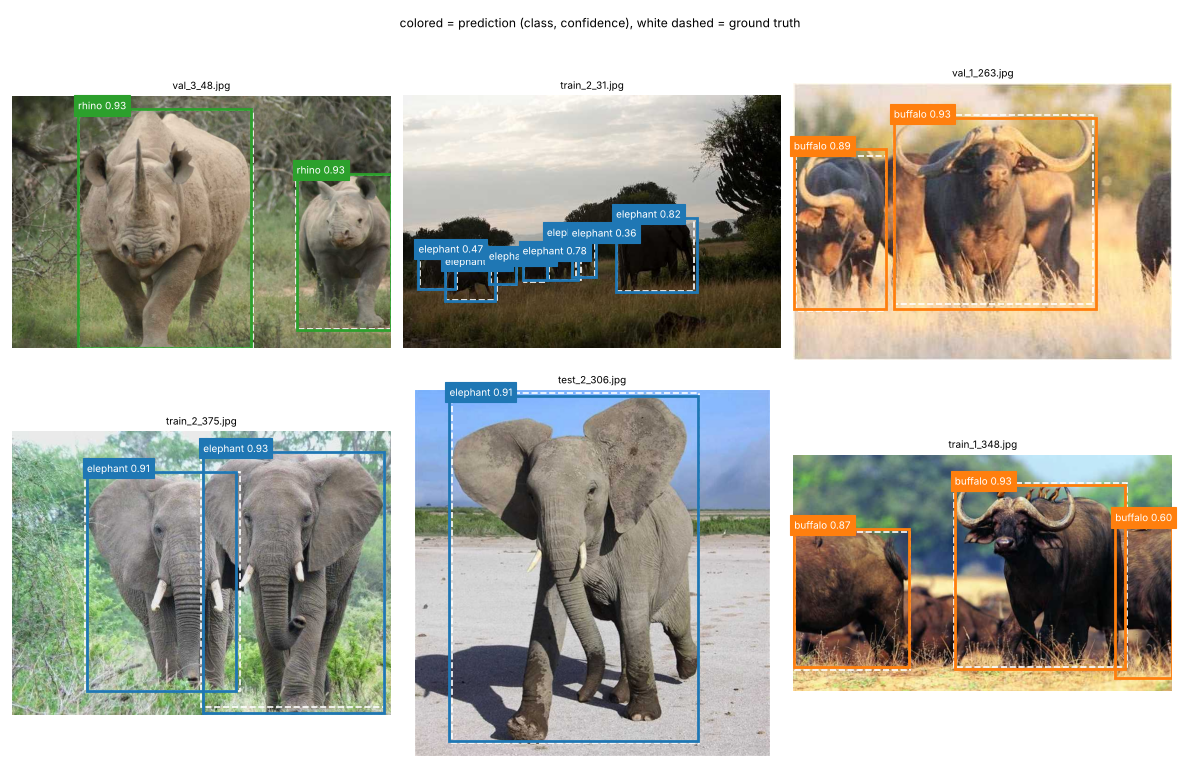

In [ ]:
!python scripts/predict_and_failures.py --run {final} --conf 0.25
preds = json.load(open("results/test_predictions.json"))
show = " ".join([p["image"] for p in preds if p["pred"] > 0][:6])
!python scripts/draw.py test results/test_predictions.png {show}
display(Image("results/test_predictions.png"))

In [ ]:
errors = [p for p in preds if p["missed"] or p["wrong_class"] or p["false_pos"]]
for p in errors[:10]:
    print(p["image"], "| missed:", p["missed"], "| wrong class:", p["wrong_class"], "| false pos:", p["false_pos"])
fail = " ".join(p["image"] for p in errors[:3])
!python scripts/draw.py test results/failures_auto.png {fail}
display(Image("results/failures_auto.png"))

test_3_233.jpg | missed: ['rhino'] | wrong class: [] | false pos: []
test_4_90.jpg | missed: ['zebra'] | wrong class: [] | false pos: []
train_1_116.jpg | missed: ['buffalo'] | wrong class: [] | false pos: []
train_1_205.jpg | missed: [] | wrong class: [] | false pos: ['zebra', 'zebra']
train_1_206.jpg | missed: ['buffalo'] | wrong class: [] | false pos: ['buffalo']
train_1_273.jpg | missed: ['zebra', 'zebra', 'zebra', 'zebra', 'buffalo', 'buffalo'] | wrong class: [] | false pos: ['buffalo']
train_1_299.jpg | missed: [] | wrong class: ['buffalo -> elephant', 'buffalo -> elephant', 'buffalo -> elephant', 'buffalo -> elephant', 'buffalo -> elephant', 'buffalo -> elephant'] | false pos: []
train_1_309.jpg | missed: [] | wrong class: [] | false pos: ['buffalo', 'buffalo', 'buffalo']
train_1_348.jpg | missed: [] | wrong class: [] | false pos: ['buffalo']
train_1_7.jpg | missed: [] | wrong class: ['buffalo -> rhino'] | false pos: ['buffalo']


Traceback (most recent call last):
  File "c:\Users\Admin\Desktop\KBTU\ДЗ\Deep Learning\bonus-task\african-wildlife-detector\scripts\draw.py", line 17, in <module>
    im = Image.open(root / "images" / split / f)
  File "c:\Users\Admin\Desktop\KBTU\ДЗ\Deep Learning\venv\Lib\site-packages\PIL\Image.py", line 3639, in open
    fp = builtins.open(filename, "rb")
FileNotFoundError: [Errno 2] No such file or directory: 'datasets\\aw-split\\images\\test\\test_3_233.jpg'


FileNotFoundError: No such file or directory: 'results/failures_auto.png'

FileNotFoundError: No such file or directory: 'results/failures_auto.png'

<IPython.core.display.Image object>